In [1]:
goals_config = {
    1: {"lat": 36.5625, "lon": -75.5, "angles": [-75, 175], "seapoint": 1904482},
    2: {"lat": 36.125, "lon": -75.25, "angles": [-75, 125], "seapoint": 1904397},
    3: {"lat": 35.6875, "lon": -75.0625, "angles": [-100, 115], "seapoint": 1904324},
    4: {"lat": 35.3125, "lon": -75.0625, "angles": [-130, 105], "seapoint": 1904228},
    5: {"lat": 34.9375, "lon": -75.375, "angles": [-150, 50], "seapoint": 1904092},
    6: {"lat": 34.75, "lon": -75.75, "angles": [-150, 40], "seapoint": 1904039},
    7: {"lat": 34.5, "lon": -76.0625, "angles": [-140, 45], "seapoint": 1903945},
    8: {"lat": 34.1875, "lon": -76.4375, "angles": [-165, 45], "seapoint": 1903794},
    9: {"lat": 34.03125, "lon": -76.96875, "angles": [-150, 30], "seapoint": 1910981},
    10: {"lat": 33.6875, "lon": -77.4375, "angles": [-155, 45], "seapoint": 1903542},
    11: {"lat": 33.40625, "lon": -77.84375, "angles": [-160, 45], "seapoint": 1910920},
    12: {"lat": 33.1875, "lon": -78.25, "angles": [-160, 45], "seapoint": 1903229},
    13: {"lat": 33, "lon": -78.625, "angles": [-160, 45], "seapoint": 1903124},
    14: {"lat": 32.875, "lon": -79, "angles": [-240, 35], "seapoint": 1903044},
}
goals_config.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

In [2]:
import pandas as pd
import xarray as xr

whacs_ds = (
    xr.open_zarr("inputs/WHACS/NorthCarolina.zarr")
    # .sel(time=slice("1986-01", "1986-03"))
    .sel(time="1986-01-18")
    .assign_coords(
        {"goal": (["seapoint"], [14, 13, 12, 10, 8, 7, 6, 5, 4, 3, 2, 1, 11, 9])}
    )
    .sortby("goal")
)


metamodel_parameters = {
    "hs_goals": [
        whacs_ds.hs.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tp_goals": [
        (1.0 / whacs_ds.fp.isel(time=itime).values).tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "wd_goals": [
        whacs_ds.dir.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "ds_goals": [
        whacs_ds.spr.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tref": pd.to_datetime(whacs_ds.time.values).strftime("%Y%m%d %H%M%S").tolist(),
}
metamodel_parameters.keys()

dict_keys(['hs_goals', 'tp_goals', 'wd_goals', 'ds_goals', 'tref'])

In [3]:
from bluemath_tk.wrappers.snapwave.snapwave_wrapper import SnapWaveDynamicModelWrapper

snapwave_wrapper = SnapWaveDynamicModelWrapper(
    templates_dir="templates-dynamic",
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={},
    output_dir="SnapWave_CASES_Dynamic",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=goals_config,
)
snapwave_wrapper

2026-06-11 14:35:29,718 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-06-11 14:35:29,718 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-06-11 14:35:29,719 - SnapWaveDynamicModelWrapper - WARNING - Parameter wd_goals is not in the default_parameters
2026-06-11 14:35:29,719 - SnapWaveDynamicModelWrapper - WARNING - Parameter ds_goals is not in the default_parameters
2026-06-11 14:35:29,720 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


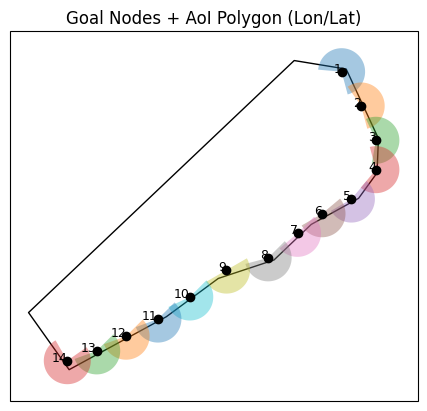

In [4]:
snapwave_wrapper.plot_configuration()

In [5]:
snapwave_wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [6]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [7]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    24
Name: count, dtype: int64

In [8]:
result = snapwave_wrapper.postprocess_cases()
result

<xarray.Dataset> Size: 285kB
Dimensions:       (time: 24, stations: 338)
Coordinates:
  * time          (time) datetime64[ns] 192B 1986-01-18 ... 1986-01-18T23:00:00
    station_name  (stations) |S256 87kB b'station_0001                    ' ....
    station_x     (stations) float32 1kB -76.23 -76.19 -76.14 ... -79.19 -77.95
    station_y     (stations) float32 1kB 37.0 36.99 36.98 ... 33.65 33.35 34.23
    point_zb      (stations) float32 1kB nan nan nan nan nan ... nan nan nan nan
Dimensions without coordinates: stations
Data variables:
    point_zs      (time, stations) float32 32kB 0.0 0.0 0.0 ... 0.0 0.0 1.372
    point_hm0     (time, stations) float32 32kB 0.0 0.0 0.0 ... 0.9876 0.0 1.042
    point_tp      (time, stations) float32 32kB 0.0 0.0 0.0 ... 7.837 0.0 7.837
    point_wavdir  (time, stations) float32 32kB 270.0 270.0 ... 270.0 138.2
    point_dw      (time, stations) float32 32kB 0.0 0.0 0.0 ... 0.0 2.399e-17
    point_df      (time, stations) float32 32kB 0.0 0.0 0.0 ... 0.0 0.07101
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

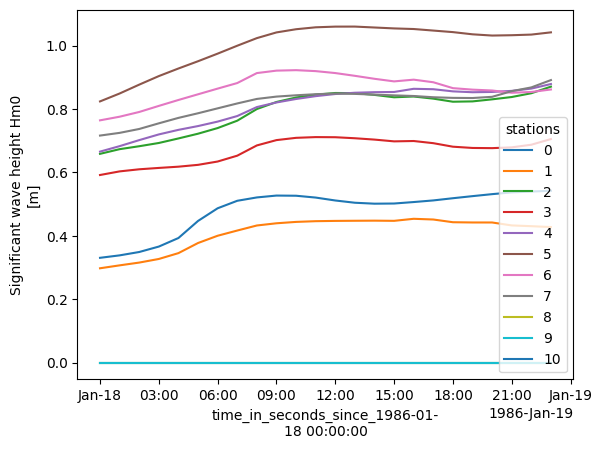

In [13]:
result.point_hm0.isel(stations=slice(None, None, 33)).plot(hue="stations");

In [14]:
result.to_netcdf("SnapWave_CASES_Dynamic/Dynamic_Cases_19860118.nc")